# 04 · Waste-type list — what avoidable waste looks like in this data
For each kind of waste: the **signature** on a meter or sub-meter, the **context** that makes the same reading normal, the **₹ formula**, the
**recommended action**, and a **safety check** (brief §9: recommend, never control; some items are never automated). The catalogue itself lives in
`src/waste_types.py` so the detector, the alert text and the UI all use the same words.

**Evidence rule.** Everything measured here comes from the **tuning window only** — anomalies that *start before 1 Apr 2026* (40 of them).
`evaluation.tuning_labels()` cannot return later rows; labels from 1 Apr 2026 are not loaded in this notebook. Waste types that the tuning window
does not contain (chilled-water setpoint, Jaipur/Goa chiller staging) are defined from the brief's waste list and the engineering guide, and are
marked as **not tuned**. Sensor data (not labels) from the whole year is used only for the context facts already in the EDA.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import detector as D, evaluation as E
from waste_types import WASTE_TYPES, NOT_DETECTED
from features import SITES

pd.set_option("display.max_columns", 40, "display.width", 220, "display.max_colwidth", 110, "display.float_format", "{:,.1f}".format)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})

TL = E.tuning_labels()
print("tuning labels:", len(TL), "| latest start:", TL.start.max(), "| cut:", E.CUT)
frames, P = D.load_all(E.tuning_label_mask)       # profiles are fitted on tuning-window hours with labelled hours removed

tuning labels: 40 | latest start: 2026-03-27 22:00:00 | cut: 2026-04-01 00:00:00


## 1 · What the tuning window contains
Nine anomaly types, 40 events. Cost is the answer key's excess cost; only used here to rank importance.

,events,sites,severity,median_hours,excess_kwh,excess_inr,share_of_inr_%
anomaly_type,,,,,,,
CHILLER_ON_LOW_LOAD,2,GGN,High,153.0,19962,156873,28.0
SIMULTANEOUS_HEAT_COOL,9,GGN,High,103.0,19505,153287,27.3
POWER_FACTOR_DROP,1,GGN,High,288.0,0,103857,18.5
AHU_SCHEDULE_OVERRIDE,6,GGN,Medium,30.0,7875,61887,11.0
EVENT_LIGHTING_LEFT_ON,9,JAI,Medium,11.0,5280,44902,8.0
POOL_PUMPS_24H,1,GOA,Low,528.0,4312,27613,4.9
KITCHEN_EXHAUST_LEFT_ON,3,GGN,Low,78.0,1320,10373,1.8
LAUNDRY_PEAK_TARIFF,7,"GGN,GOA,JAI",Low,4.0,0,1944,0.3
METER_DATA_FAULT,2,"GGN,JAI",Data quality,11.1,0,0,0.0


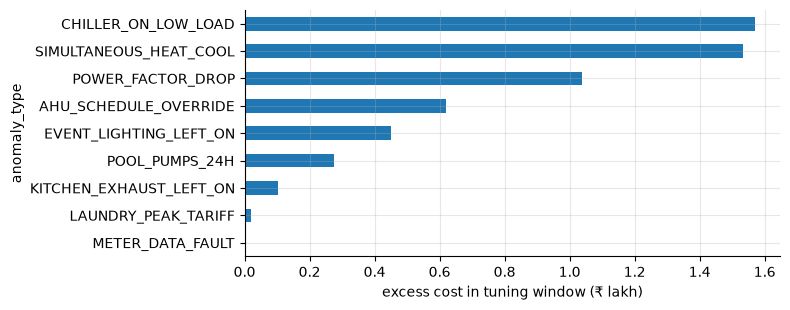

In [2]:
TL["hours"] = (TL.end - TL.start).dt.total_seconds() / 3600
T = TL.groupby("anomaly_type").agg(events=("anomaly_id", "size"), sites=("site", lambda x: ",".join(sorted(set(x)))), severity=("severity", lambda x: "/".join(sorted(set(x)))),
                                   median_hours=("hours", "median"), excess_kwh=("excess_kwh", "sum"), excess_inr=("excess_cost_inr", "sum"))
T["share_of_inr_%"] = T.excess_inr / T.excess_inr.sum() * 100
display(T.sort_values("excess_inr", ascending=False))
fig, ax = plt.subplots(figsize=(8, 3.2))
T.sort_values("excess_inr").excess_inr.div(1e5).plot.barh(ax=ax, color="#1f77b4"); ax.set_xlabel("excess cost in tuning window (₹ lakh)")
plt.tight_layout(); plt.show()

## 2 · Signature evidence
For each type, the equipment reading **during the labelled hours** vs **unlabelled hours in the same context** (same hours of day / event state /
plant-load band). A usable signature has a large gap and no overlap with normal operation. Numbers are computed here, not typed in.

In [3]:
def typemask(site, typ):
    f = frames[site]; m = pd.Series(False, index=f.index)
    for r in TL.query("site == @site and anomaly_type == @typ").itertuples():
        m |= (f.timestamp >= r.start) & (f.timestamp < r.end)
    return m

def compare(site, typ, col, ctx=None, unit="kW"):
    f = frames[site]; lab = typemask(site, typ); anyl = E.tuning_label_mask(site, f.timestamp)
    ctx = pd.Series(True, index=f.index) if ctx is None else ctx
    inwin = f.timestamp < E.CUT
    a = f.loc[lab & ctx & inwin & ~f.fault, col]; n = f.loc[~anyl & ctx & inwin & f.valid & ~f.fault, col]
    return dict(type=typ, site=site, signal=col, unit=unit, hours_labelled=len(a), anomalous_mean=a.mean(), normal_mean=n.mean(), normal_p99=n.quantile(.99),
                normal_min=n.min(), normal_max=n.max(), anomalous_min=a.min(), anomalous_max=a.max(), separation_x=(a.mean() / n.mean()) if n.mean() > 0 else np.inf)

g, j, o = frames["GGN"], frames["JAI"], frames["GOA"]
rows = [
    compare("GGN", "AHU_SCHEDULE_OVERRIDE", "ahu_banquet_kw", ~g.event_on),
    compare("GGN", "SIMULTANEOUS_HEAT_COOL", "ahu_heaters_kw", g.hour.between(10, 16)),
    compare("GGN", "KITCHEN_EXHAUST_LEFT_ON", "kitchen_exhaust_kw", g.hour.between(0, 5)),
    compare("JAI", "EVENT_LIGHTING_LEFT_ON", "lighting_kw", j.hour.between(0, 5) & ~j.event_on),
    compare("GGN", "LAUNDRY_PEAK_TARIFF", "laundry_kw", g.peak_window),
    compare("JAI", "LAUNDRY_PEAK_TARIFF", "laundry_kw", j.peak_window),
    compare("GOA", "POOL_PUMPS_24H", "pool_pump_kw", o.hour.isin(list(range(17, 24)) + list(range(0, 7)))),
    compare("GGN", "CHILLER_ON_LOW_LOAD", "chillers_kw", (g.chiller_load_tr < 130)),
]
S = pd.DataFrame(rows)
# derived signals need a small computation
g_pf = (g.grid_kwh / g.grid_kvah).where(~g.is_dg & (g.grid_kvah > 0)); g["pf"] = g_pf
S = pd.concat([S, pd.DataFrame([compare("GGN", "POWER_FACTOR_DROP", "pf", None, "ratio")])], ignore_index=True)
g["kwtr"] = g.chillers_kw / g.chiller_load_tr.where(g.chiller_load_tr > 0)
S = pd.concat([S, pd.DataFrame([compare("GGN", "CHILLER_ON_LOW_LOAD", "kwtr", g.chiller_load_tr < 130, "kW/TR")])], ignore_index=True)
display(S.drop(columns=["unit"]).round(3))
# a signature is clean when the anomalous readings sit entirely outside the normal range (above it; below it for power factor)
S["clean"] = np.where(S.signal.eq("pf"), S.anomalous_max < S.normal_min, S.anomalous_min > S.normal_max)
S["margin_x"] = np.where(S.signal.eq("pf"), S.normal_min / S.anomalous_max, S.anomalous_min / S.normal_max.replace(0, np.nan))
print("every signature clears normal operation:", bool(S.clean.all()))
display(S[["type", "site", "signal", "clean", "margin_x"]].round(2))

,type,site,signal,hours_labelled,anomalous_mean,normal_mean,normal_p99,normal_min,normal_max,anomalous_min,anomalous_max,separation_x
0,AHU_SCHEDULE_OVERRIDE,GGN,ahu_banquet_kw,140,45.0,0.0,0.0,0.0,0.0,43.9,46.2,inf
1,SIMULTANEOUS_HEAT_COOL,GGN,ahu_heaters_kw,224,87.6,0.3,9.1,0.0,29.1,45.5,273.6,303.4
2,KITCHEN_EXHAUST_LEFT_ON,GGN,kitchen_exhaust_kw,60,22.0,0.0,0.0,0.0,0.0,21.6,22.5,inf
3,EVENT_LIGHTING_LEFT_ON,JAI,lighting_kw,36,89.3,34.0,34.8,32.9,34.9,87.2,91.2,2.6
4,LAUNDRY_PEAK_TARIFF,GGN,laundry_kw,20,73.2,0.0,0.0,0.0,0.0,65.5,80.4,inf
5,LAUNDRY_PEAK_TARIFF,JAI,laundry_kw,4,54.4,0.0,0.0,0.0,0.0,54.0,55.1,inf
6,POOL_PUMPS_24H,GOA,pool_pump_kw,308,24.0,10.0,10.2,9.7,10.3,23.2,24.7,2.4
7,CHILLER_ON_LOW_LOAD,GGN,chillers_kw,217,116.8,51.9,74.7,39.8,76.8,102.7,145.8,2.2
8,POWER_FACTOR_DROP,GGN,pf,288,0.9,1.0,1.0,1.0,1.0,0.9,0.9,0.9
9,CHILLER_ON_LOW_LOAD,GGN,kwtr,217,1.5,0.7,0.7,0.6,0.7,1.0,1.9,2.3


every signature clears normal operation: True


,type,site,signal,clean,margin_x
0,AHU_SCHEDULE_OVERRIDE,GGN,ahu_banquet_kw,True,NaN
1,SIMULTANEOUS_HEAT_COOL,GGN,ahu_heaters_kw,True,1.6
2,KITCHEN_EXHAUST_LEFT_ON,GGN,kitchen_exhaust_kw,True,NaN
3,EVENT_LIGHTING_LEFT_ON,JAI,lighting_kw,True,2.5
4,LAUNDRY_PEAK_TARIFF,GGN,laundry_kw,True,NaN
5,LAUNDRY_PEAK_TARIFF,JAI,laundry_kw,True,NaN
6,POOL_PUMPS_24H,GOA,pool_pump_kw,True,2.2
7,CHILLER_ON_LOW_LOAD,GGN,chillers_kw,True,1.3
8,POWER_FACTOR_DROP,GGN,pf,True,1.1
9,CHILLER_ON_LOW_LOAD,GGN,kwtr,True,1.5


Reading the table: laundry, kitchen exhaust and banquet AHUs are effectively "on vs off" (no overlap with normal at all). For Jaipur lighting, the Goa pump and
chiller kW the anomalous minimum is ~2x the highest normal reading. The **thinnest margin is AHU re-heat** (anomalous min 45 kW vs a normal maximum of 29 kW, at the same
hours of day), which is why that rule compares against a profile by hour *and* outdoor-temperature band and adds the guide's 16 °C interlock, instead of using one threshold.
Power factor is a *drop*, so its margin is read the other way round (normal minimum vs anomalous maximum). The chiller rule also requires **two chillers running**, not only a high kW.

## 3 · Context that must *not* alert
Same equipment, normal readings that look like waste to a threshold alarm. The profile (hour × context) is what separates them.

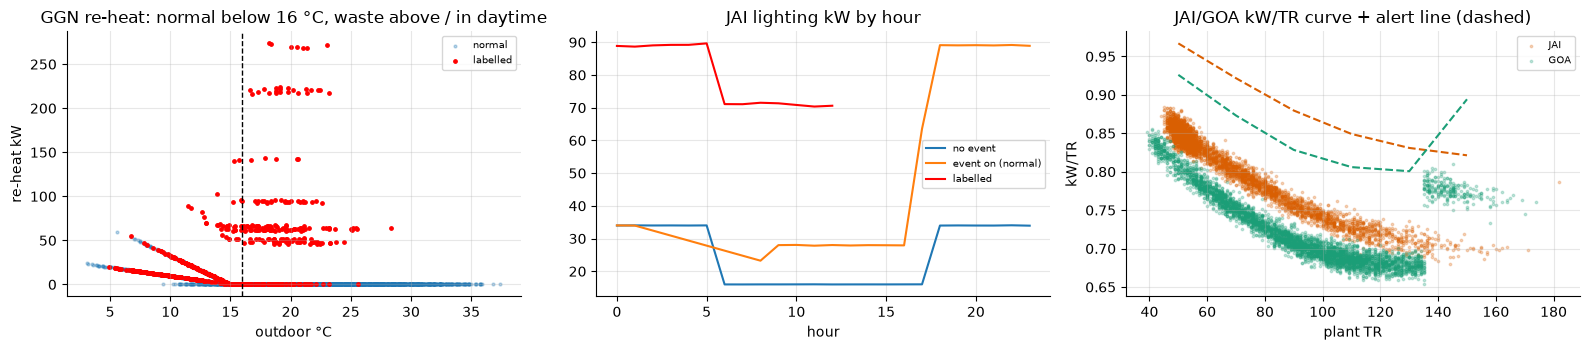

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6))
# (a) GGN heaters vs outdoor temperature, labelled vs normal
f = g[(g.timestamp < E.CUT) & g.valid]
lab = typemask("GGN", "SIMULTANEOUS_HEAT_COOL")[f.index]
ax[0].scatter(f.temp_c[~lab], f.ahu_heaters_kw[~lab], s=4, alpha=.3, label="normal"); ax[0].scatter(f.temp_c[lab], f.ahu_heaters_kw[lab], s=6, color="r", label="labelled")
ax[0].axvline(16, color="k", ls="--", lw=1); ax[0].set_xlabel("outdoor °C"); ax[0].set_ylabel("re-heat kW"); ax[0].set_title("GGN re-heat: normal below 16 °C, waste above / in daytime"); ax[0].legend(fontsize=7)
# (b) JAI lighting by hour, event nights vs not
f = j[(j.timestamp < E.CUT) & j.valid]; lab = typemask("JAI", "EVENT_LIGHTING_LEFT_ON")[f.index]
ax[1].plot(f[~lab & ~f.event_on].groupby("hour").lighting_kw.mean(), label="no event"); ax[1].plot(f[~lab & f.event_on].groupby("hour").lighting_kw.mean(), label="event on (normal)")
ax[1].plot(f[lab].groupby("hour").lighting_kw.mean(), color="r", label="labelled"); ax[1].set_title("JAI lighting kW by hour"); ax[1].set_xlabel("hour"); ax[1].legend(fontsize=7)
# (c) Chiller plant kW/TR vs plant load for JAI / GOA: curve + noise
for s, c in (("JAI", "#d95f02"), ("GOA", "#1b9e77")):
    f = frames[s]; f = f[(f.timestamp < E.CUT) & f.valid & (f.chiller_load_tr > 0)]
    ax[2].scatter(f.chiller_load_tr, f.chillers_kw / f.chiller_load_tr, s=3, alpha=.25, color=c, label=s)
    x, y = P.kwtr_curve[s]; ax[2].plot(x, y + D.KWTR_MARGIN, color=c, lw=1.5, ls="--")
ax[2].set_xlabel("plant TR"); ax[2].set_ylabel("kW/TR"); ax[2].set_title("JAI/GOA kW/TR curve + alert line (dashed)"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

## 4 · Types not in the tuning window (defined from the brief / guide, **not tuned**)
- **Chilled-water setpoint low.** The CHW setpoint is **7.0 °C in every hour of the tuning window** — there is no example to tune on. The rule is the guide's:
  standard 7.0 °C, never below 6.5 °C, ~3–4 % more chiller power per °C. The BMS command log shows setpoint changes; the detector cites the last one.
- **Chiller staging at Jaipur / Goa.** Only `chillers_kw` and plant TR exist (no per-chiller meter), so the signature is "kW/TR above the learned curve for that load".
  The tuning window has no such label for these hotels, so the margin is set from the noise of the curve (σ ≈ 0.02 kW/TR → margin 0.12).
- **Hand-mode AHUs.** The BMS log records entering hand mode (`Banquet AHU mode` 1 → 2) but never leaving it; so "since when" is read from the AHU kW and the events calendar, and
  the log entry is used as supporting evidence only.

In [5]:
cmd = pd.read_parquet(ROOT / "data/clean/bms_command_log.parquet")
cmd = cmd[cmd.timestamp < E.CUT]
print("BMS command log, tuning window:", cmd.point.value_counts().to_dict())
print("CHW supply setpoint changes before the cut:", int((cmd.point == "CHW supply setpoint").sum()),
      "| distinct setpoint values in tuning-window sub-meter data:", sorted(g[g.timestamp < E.CUT].chw_setpoint_c.unique()))
hm = cmd[cmd.point == "Banquet AHU mode"]
print("hand-mode entries logged:", len(hm), "| with a matching 'return to auto' entry:", int((hm.new_value == 1).sum()))

BMS command log, tuning window: {'CHILLER_CH3 run command': 192, 'CHILLER_CH1 run command': 179, 'Banquet AHU mode': 6}
CHW supply setpoint changes before the cut: 0 | distinct setpoint values in tuning-window sub-meter data: [np.float64(7.0)]
hand-mode entries logged: 6 | with a matching 'return to auto' entry: 0


## 5 · Does the ₹ formula agree with the answer key?
Run the detector over the tuning window and compare **our** ₹ (from kW, tariff and PF) with the key's excess cost for the labels each alert overlaps.
Close agreement means the costing is right for the types where the key has a cost; the key cost is *not* used to compute ours.

In [6]:
al = D.detect_all(frames, P)
al_t = al[al.start < E.CUT]
rows = []
for typ, rule in {"AHU_SCHEDULE_OVERRIDE": "AHU_HAND_MODE", "SIMULTANEOUS_HEAT_COOL": "HEAT_COOL_FIGHT", "KITCHEN_EXHAUST_LEFT_ON": "KITCHEN_EXHAUST_OFF_HOURS",
                  "EVENT_LIGHTING_LEFT_ON": "LIGHTING_LEFT_ON", "LAUNDRY_PEAK_TARIFF": "LAUNDRY_IN_PEAK", "POOL_PUMPS_24H": "POOL_PUMP_OFF_SCHEDULE",
                  "POWER_FACTOR_DROP": "POWER_FACTOR_DROP", "CHILLER_ON_LOW_LOAD": "CHILLER_STAGING_LOW_LOAD"}.items():
    L = TL[TL.anomaly_type == typ]
    # alerts of this rule that overlap a label of this type (an alert can span several overlapping labels, so compare totals)
    A = al_t[al_t.rule == rule]
    hit = [a for a in A.itertuples() if ((L.site == a.site) & E._overlap(a.start, a.end, L.start, L.end)).any()]
    ours = sum(a.cost_inr for a in hit)
    rows.append(dict(type=typ, key_inr=L.excess_cost_inr.sum(), our_inr=ours, ratio=ours / L.excess_cost_inr.sum() if L.excess_cost_inr.sum() else np.nan, key_kwh=L.excess_kwh.sum(),
                     our_kwh=sum(a.excess_kwh for a in hit)))
C = pd.DataFrame(rows); display(C.round(2))

,type,key_inr,our_inr,ratio,key_kwh,our_kwh
0,AHU_SCHEDULE_OVERRIDE,61887,"49,454.9",0.8,7875,"6,294.3"
1,SIMULTANEOUS_HEAT_COOL,153287,"153,894.3",1.0,19505,"19,586.7"
2,KITCHEN_EXHAUST_LEFT_ON,10373,"10,383.2",1.0,1320,"1,321.5"
3,EVENT_LIGHTING_LEFT_ON,44902,"44,928.7",1.0,5280,"5,283.3"
4,LAUNDRY_PEAK_TARIFF,1944,"1,938.8",1.0,0,0.0
5,POOL_PUMPS_24H,27613,"27,617.1",1.0,4312,"4,312.7"
6,POWER_FACTOR_DROP,103857,"103,784.0",1.0,0,0.0
7,CHILLER_ON_LOW_LOAD,156873,"114,545.9",0.7,19962,"14,578.6"


Ratios of ~1.0 for six types mean the tariff-based formula agrees with the key. The two lower ratios are conservative by construction: we cost only hours where the
signature holds. For the banquet AHUs, the 35 labelled hours with another event active are not counted as waste; for staging, 217 of the 251 labelled hours have two
chillers below 130 TR (the other 34 are CH-1 alone at ~143 TR, which is not the staging fault). Estimates should be shown as "excess vs normal", not as exact.

## 6 · The catalogue
One row per waste type: signature, what suppresses an alert, ₹ formula, action, guardrail class, and whether it was tuned on tuning-window labels.

In [7]:
cat = pd.DataFrame(WASTE_TYPES).T
cat["tuned_on_tuning_labels"] = cat.maps_to_labels.map(lambda v: "yes" if any(t in set(TL.anomaly_type) for t in v) else "no")
cat.loc["METER_DATA_FAULT", "tuned_on_tuning_labels"] = "yes"
cat.loc["CHILLER_PART_LOAD_INEFFICIENCY", "tuned_on_tuning_labels"] = "no (guide + curve noise)"
cat.loc["CHW_SETPOINT_LOW", "tuned_on_tuning_labels"] = "no (guide only)"
display(cat[["label", "sites", "severity", "guardrail", "tuned_on_tuning_labels"]])
for k, v in WASTE_TYPES.items():
    print(f"\n{k} — {v['label']}\n  signature: {v['signature']}\n  not an alert when: {v['context_suppressor']}\n  ₹: {v['cost']}\n  action: {v['action']}")

,label,sites,severity,guardrail,tuned_on_tuning_labels
AHU_HAND_MODE,Banquet AHUs running with no event,[GGN],Medium,auto-ok,yes
HEAT_COOL_FIGHT,AHU re-heat on while cooling / outdoor air warm,[GGN],High,auto-ok,yes
KITCHEN_EXHAUST_OFF_HOURS,Kitchen exhaust / make-up air running after the kitchen closed,[GGN],Low,never,yes
LIGHTING_LEFT_ON,Event / facade lighting left on,"[GGN, JAI, GOA]",Medium,auto-ok,yes
LAUNDRY_IN_PEAK,Laundry running in the peak tariff window,"[GGN, JAI, GOA]",Low,recommend,yes
POOL_PUMP_OFF_SCHEDULE,Pool pumps running outside their schedule,"[JAI, GOA]",Low,recommend,yes
POWER_FACTOR_DROP,Power factor drop (failed APFC capacitor step),"[GGN, JAI, GOA]",High,recommend,yes
CHILLER_STAGING_LOW_LOAD,Two chillers running at low load,[GGN],High,auto-ok,yes
CHILLER_PART_LOAD_INEFFICIENCY,Chiller plant kW/TR far above normal for the load,"[JAI, GOA]",High,auto-ok,no (guide + curve noise)
CHW_SETPOINT_LOW,Chilled-water setpoint below standard,[GGN],Medium,auto-ok,no (guide only)



AHU_HAND_MODE — Banquet AHUs running with no event
  signature: Banquet AHU kW stays near rated (~45 kW per unit) after the event end + 1 h buffer, with no other event in the calendar.
  not an alert when: Any event active in the hour (start - 1 h to end + 1 h; past-midnight events assumed to end 01:00).
  ₹: excess_kW x hours x grid marginal rate (energy + FSA + duty) / PF
  action: Return banquet AHUs to schedule at the BMS (they were left in hand mode at the local panel); schedule from the events calendar, start 1 h before, stop 1 h after.

HEAT_COOL_FIGHT — AHU re-heat on while cooling / outdoor air warm
  signature: AHU electric re-heat kW far above what is normal for that hour and outdoor temperature (the guide allows re-heat only below 16 degC).
  not an alert when: Normal winter re-heat for the same hour and outdoor-temperature band is learned from the tuning window and is not flagged.
  ₹: excess_kW x hours x grid marginal rate; plus the chiller kWh spent cooling the same air

## 7 · Safety check on each recommended action
Applies the brief's automation table and engineering limits to every action in the catalogue. No row may advise a CHW setpoint under 6.5 °C, touch
kitchen exhaust during service, change guest-room thermostats, or act on fire / life-safety / lifts.

In [8]:
import re
checks = []
for k, v in WASTE_TYPES.items():
    a = v["action"].lower()
    checks.append(dict(type=k, guardrail=v["guardrail"],
                       mentions_setpoint_below_6_5=bool(re.search(r"(?<![\d.])([0-5](\.\d+)?|6\.[0-4]\d*)\s*degc", a)),
                       touches_life_safety=any(w in a for w in ["lift", "fire", "pressuris"]),
                       touches_room_thermostat="thermostat" in a,
                       auto_off_kitchen_exhaust=("exhaust" in a and "automatic" in a and "never" not in a and "interlock" not in a)))
chk = pd.DataFrame(checks).set_index("type"); display(chk)
assert not chk.drop(columns="guardrail").any().any(), "an action violates a guardrail"
assert WASTE_TYPES["KITCHEN_EXHAUST_OFF_HOURS"]["guardrail"] == "never"
print("all", len(chk), "catalogue actions pass the guardrail checks; kitchen exhaust is 'never automate' (T10)")

,guardrail,mentions_setpoint_below_6_5,touches_life_safety,touches_room_thermostat,auto_off_kitchen_exhaust
type,,,,,
AHU_HAND_MODE,auto-ok,False,False,False,False
HEAT_COOL_FIGHT,auto-ok,False,False,False,False
KITCHEN_EXHAUST_OFF_HOURS,never,False,False,False,False
LIGHTING_LEFT_ON,auto-ok,False,False,False,False
LAUNDRY_IN_PEAK,recommend,False,False,False,False
POOL_PUMP_OFF_SCHEDULE,recommend,False,False,False,False
POWER_FACTOR_DROP,recommend,False,False,False,False
CHILLER_STAGING_LOW_LOAD,auto-ok,False,False,False,False
CHILLER_PART_LOAD_INEFFICIENCY,auto-ok,False,False,False,False


all 11 catalogue actions pass the guardrail checks; kitchen exhaust is 'never automate' (T10)


## 8 · What the product cannot see (state this in the UI)
Detectability floor per signal: the rule's minimum kW, next to the noise left *after* removing context (spread within the same hour / event / temperature cell) in unlabelled tuning hours. A floor above the noise means the deviation is separable. (Laundry and banquet AHU are on/off loads, so their spread is the normal on/off pattern, not measurement noise.)

In [9]:
floor = []
for s in D.SITES:
    f = frames[s]; ok = (f.timestamp < D.CUT) & f.valid & ~f.fault & ~E.tuning_label_mask(s, f.timestamp)
    mean_load = f.total_kwh[ok].mean()
    KEYS = dict(lighting_kw=["hour", "event_on"], laundry_kw=["hour"], pool_pump_kw=["hour"], ahu_banquet_kw=["event_on"], ahu_heaters_kw=["hour", "tband"], kitchen_exhaust_kw=["hour"])
    for col, nm in (("lighting_kw", "lighting"), ("laundry_kw", "laundry"), ("pool_pump_kw", "pool pumps"), ("ahu_banquet_kw", "banquet AHU"), ("ahu_heaters_kw", "AHU re-heat"), ("kitchen_exhaust_kw", "kitchen exhaust")):
        if col in f and f[col].notna().any():
            cell_sd = float(np.sqrt(f.loc[ok].groupby(KEYS[col])[col].var().mean()))
            floor.append(dict(site=s, signal=nm, rule_floor_kw=dict(lighting_kw=D.KW_FLOOR["LIGHTING"], laundry_kw=D.KW_FLOOR["LAUNDRY"], pool_pump_kw=D.KW_FLOOR["POOL"],
                                                                      ahu_banquet_kw=D.KW_FLOOR["AHU"], ahu_heaters_kw=D.KW_FLOOR["HEATER"], kitchen_exhaust_kw=D.KW_FLOOR["KITCHEN"])[col],
                              normal_noise_kw=cell_sd, site_mean_kw=mean_load))
    r = f.resid[ok]; floor.append(dict(site=s, signal="whole-site residual", rule_floor_kw=D.RESID["floor_frac"] * mean_load, normal_noise_kw=r.std(), site_mean_kw=mean_load))
F = pd.DataFrame(floor); F["floor_%_of_site"] = F.rule_floor_kw / F.site_mean_kw * 100; display(F.round(1))
print("\nNot detected:"); 
for x in NOT_DETECTED:
    print(" -", x)

,site,signal,rule_floor_kw,normal_noise_kw,site_mean_kw,floor_%_of_site
0,GGN,lighting,8.0,1.1,426.4,1.9
1,GGN,laundry,10.0,16.0,426.4,2.3
2,GGN,banquet AHU,10.0,15.6,426.4,2.3
3,GGN,AHU re-heat,5.0,2.1,426.4,1.2
4,GGN,kitchen exhaust,5.0,0.2,426.4,1.2
5,GGN,whole-site residual,34.1,20.8,426.4,8.0
6,JAI,lighting,8.0,2.9,248.2,3.2
7,JAI,laundry,10.0,12.0,248.2,4.0
8,JAI,pool pumps,5.0,0.1,248.2,2.0
9,JAI,whole-site residual,19.9,7.8,248.2,8.0



Not detected:
 - Waste smaller than the sub-meter noise (a few kW on a 600 kW site hidden in 'other' or unmetered load).
 - Hand-mode overrides on equipment other than banquet AHUs: the BMS log records entering hand mode but never leaving it.
 - Waste in equipment with no sub-meter (unmetered 'other' load is 8-14% of site energy).
 - Comfort breaches (guest-room temperatures are not in the data), so 'too hot' is never judged.


## 9 · Takeaways
- Nine waste types appear in the tuning window; eight have a clean sub-meter or PF signature, and the ninth is the meter fault, which has its own stream (T5).
- The CHW setpoint and the Jaipur/Goa staging rule are **defined but untuned**: the tuning window has no example, so they rest on the guide, and their precision is only known from the 1 Apr scoring in notebook 05.
- Costing reproduces the key's ₹ (section 5) closely enough to show as an estimate; alerts say "excess vs normal".
- The whole-site residual floor is 8 % of load, so small loads hidden in unmetered "other" are invisible by design. This goes in the UI as "what the product can't see".